# Atividade 3: Classificador com CNN pré-treinada

**Aluno:** Anderson Corrêa

**Objetivo:** classificar fotos de objetos usando transfer learning por feature extraction. A ResNet-50 pré-treinada na ImageNet fica congelada e só a última camada é treinada.

**Requisitos de execução**

- Ambiente: Google Colab com GPU T4
- Memória de GPU: menos de 4 GB
- Memória RAM: menos de 4 GB
- Disco: 2 GB livres
- Tempo estimado: menos de 15 minutos

**Como executar:** menu *Ambiente de execução*, *Executar tudo*. O notebook baixa os dados sozinho e não precisa de login.

In [ ]:
import json
import random
import time
from pathlib import Path
from shutil import make_archive

import numpy as np
import torch
from torch.utils.data import DataLoader

SEED = 42
BATCH_SIZE = 32
EPOCHS = 10
LEARNING_RATE = 1e-3
DATASET_SLUG = "pavansanagapati/images-dataset"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = Path("data/images_dataset")
OUTPUT_DIR = Path("outputs/a3")
FIGURES_DIR = OUTPUT_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
STARTED_AT = time.time()

print("dispositivo:", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")


dispositivo: Tesla T4


## Código de apoio

As quatro células abaixo definem as funções usadas no restante do notebook: dados, laço de treino, modelo e gráficos.

In [ ]:
"""Dataset download, image discovery and splitting shared by the notebooks."""

from collections import Counter
from pathlib import Path
from zipfile import ZipFile

from PIL import Image
from requests import get
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset

KAGGLE_DOWNLOAD_URL = "https://www.kaggle.com/api/v1/datasets/download/{slug}"
IMAGE_SUFFIXES = {".bmp", ".jpg", ".jpeg", ".png"}
MINIMUM_IMAGES_PER_CLASS = 7


def download_kaggle_dataset(slug: str, destination: Path) -> Path:
    """Downloads and extracts a public Kaggle dataset, once.

    A marker file records a finished download, so calling this again for the
    same destination returns immediately. No Kaggle account is needed.
    """
    destination = Path(destination)
    marker = destination / ".complete"
    if marker.exists():
        return destination
    destination.mkdir(parents=True, exist_ok=True)
    archive = destination / "archive.zip"
    with get(KAGGLE_DOWNLOAD_URL.format(slug=slug), stream=True, timeout=60) as response:
        response.raise_for_status()
        with open(archive, "wb") as handle:
            for chunk in response.iter_content(chunk_size=1 << 20):
                handle.write(chunk)
    with ZipFile(archive) as bundle:
        bundle.extractall(destination)
    archive.unlink()
    marker.touch()
    return destination


def is_readable_image(path: Path) -> bool:
    """Tells whether a file is a visible image that Pillow can decode."""
    if path.name.startswith(".") or path.suffix.lower() not in IMAGE_SUFFIXES:
        return False
    try:
        with Image.open(path) as image:
            image.load()
    except (OSError, SyntaxError, ValueError):
        return False
    return True


def list_image_folder(root: Path) -> tuple[list[Path], list[int], list[str]]:
    """Finds every readable image under root and labels it by its parent folder.

    Returns the image paths, one integer label per path, and the class names
    in the order used by the labels. Unreadable files are left out.
    """
    paths = sorted(path for path in Path(root).rglob("*") if path.is_file() and is_readable_image(path))
    class_names = sorted({path.parent.name for path in paths})
    index = {name: position for position, name in enumerate(class_names)}
    labels = [index[path.parent.name] for path in paths]
    return paths, labels, class_names


def stratified_split(
    labels: list[int],
    fractions: tuple[float, float, float] = (0.7, 0.15, 0.15),
    seed: int = 42,
) -> tuple[list[int], list[int], list[int]]:
    """Splits indices into train, validation and test, keeping class shares.

    Raises ValueError naming the class when a class is too small to appear in
    all three parts.
    """
    for label, count in sorted(Counter(labels).items()):
        if count < MINIMUM_IMAGES_PER_CLASS:
            raise ValueError(
                f"class {label} has {count} images; at least {MINIMUM_IMAGES_PER_CLASS} are needed to split"
            )
    indices = list(range(len(labels)))
    train, rest = train_test_split(
        indices, train_size=fractions[0], stratify=labels, random_state=seed
    )
    validation_share = fractions[1] / (fractions[1] + fractions[2])
    validation, test = train_test_split(
        rest,
        train_size=validation_share,
        stratify=[labels[i] for i in rest],
        random_state=seed,
    )
    return sorted(train), sorted(validation), sorted(test)


class ImageListDataset(Dataset):
    """Serves transformed images and labels from parallel lists."""

    def __init__(self, paths: list[Path], labels: list[int], transform):
        """Stores the image paths, their labels and the transform to apply."""
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self) -> int:
        """Returns the number of images."""
        return len(self.paths)

    def __getitem__(self, index: int):
        """Loads one image as RGB and returns it transformed, with its label."""
        with Image.open(self.paths[index]) as image:
            return self.transform(image.convert("RGB")), self.labels[index]


In [ ]:
"""Training loop and evaluation for image classifiers."""

import torch
from torch import nn
from torch.nn.functional import cross_entropy


def train_all(model: nn.Module) -> None:
    """Puts every layer of the model in training mode."""
    model.train()


def run_epoch(model, loader, device, optimizer=None) -> tuple[float, float]:
    """Runs one pass over a loader and returns mean loss and accuracy.

    The model is updated only when an optimizer is given. An empty loader
    yields zeros.
    """
    training = optimizer is not None
    total_loss = 0.0
    correct = 0
    count = 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            logits = model(images)
            loss = cross_entropy(logits, labels)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            count += labels.size(0)
    return total_loss / max(count, 1), correct / max(count, 1)


def fit(
    model,
    train_loader,
    validation_loader,
    optimizer,
    epochs: int,
    device,
    set_train_mode=train_all,
) -> dict[str, list[float]]:
    """Trains a classifier and returns loss and accuracy for every epoch.

    ``set_train_mode`` decides which layers train. Pass a custom function to
    keep a frozen backbone in evaluation mode.
    """
    history = {"train_loss": [], "train_accuracy": [], "val_loss": [], "val_accuracy": []}
    for epoch in range(epochs):
        set_train_mode(model)
        train_loss, train_accuracy = run_epoch(model, train_loader, device, optimizer)
        model.eval()
        val_loss, val_accuracy = run_epoch(model, validation_loader, device)
        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)
        print(
            f"epoch {epoch + 1}/{epochs} "
            f"train loss {train_loss:.4f} acc {train_accuracy:.4f} "
            f"val loss {val_loss:.4f} acc {val_accuracy:.4f}"
        )
    return history


def evaluate(model, loader, device, num_classes: int) -> dict:
    """Measures overall accuracy, accuracy per class and the confusion matrix.

    Confusion rows are true classes and columns are predicted classes.
    """
    model.eval()
    confusion = torch.zeros(num_classes, num_classes, dtype=torch.long)
    with torch.no_grad():
        for images, labels in loader:
            predictions = model(images.to(device)).argmax(dim=1).cpu()
            for truth, prediction in zip(labels.tolist(), predictions.tolist()):
                confusion[truth, prediction] += 1
    hits = confusion.diag()
    per_class = (hits / confusion.sum(dim=1).clamp(min=1)).tolist()
    accuracy = (hits.sum() / confusion.sum().clamp(min=1)).item()
    return {
        "accuracy": accuracy,
        "per_class_accuracy": per_class,
        "confusion": confusion.tolist(),
    }


In [ ]:
"""Transfer learning by feature extraction with a pre-trained ResNet-50."""

from torch import nn
from torchvision.models import ResNet50_Weights, resnet50
from torchvision.transforms import CenterCrop, Compose, Normalize, Resize, ToTensor

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


def build_feature_extractor(num_classes: int, pretrained: bool = True) -> nn.Module:
    """Builds a ResNet-50 whose backbone is frozen and whose head is new.

    Every backbone weight stops receiving gradients. The classification head
    is replaced by a fresh linear layer with one output per class, which is
    the only trainable part.
    """
    weights = ResNet50_Weights.IMAGENET1K_V2 if pretrained else None
    model = resnet50(weights=weights)
    for parameter in model.parameters():
        parameter.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model


def set_feature_extraction_mode(model: nn.Module) -> None:
    """Keeps the frozen backbone in evaluation mode while the head trains.

    Batch normalization layers update their running statistics in training
    mode even when their weights are frozen, so the backbone must stay in
    evaluation mode to remain a fixed feature extractor.
    """
    model.eval()
    model.fc.train()


def trainable_parameters(model: nn.Module) -> list:
    """Returns the parameters that receive gradients."""
    return [parameter for parameter in model.parameters() if parameter.requires_grad]


def imagenet_transform(image_size: int = 224) -> Compose:
    """Returns the preprocessing used when the backbone was pre-trained."""
    return Compose(
        [
            Resize(232),
            CenterCrop(image_size),
            ToTensor(),
            Normalize(IMAGENET_MEAN, IMAGENET_STD),
        ]
    )


In [ ]:
"""Plots used by the notebooks and the report. Labels are in Portuguese."""

from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.figure import Figure


def plot_history(history: dict, path: Path) -> Figure:
    """Draws loss and accuracy per epoch for training and validation."""
    epochs = range(1, len(history["train_loss"]) + 1)
    figure, (loss_axis, accuracy_axis) = plt.subplots(1, 2, figsize=(11, 4))
    loss_axis.plot(epochs, history["train_loss"], marker="o", label="Treino")
    loss_axis.plot(epochs, history["val_loss"], marker="o", label="Validação")
    loss_axis.set_xlabel("Época")
    loss_axis.set_ylabel("Perda")
    loss_axis.legend()
    accuracy_axis.plot(epochs, history["train_accuracy"], marker="o", label="Treino")
    accuracy_axis.plot(epochs, history["val_accuracy"], marker="o", label="Validação")
    accuracy_axis.set_xlabel("Época")
    accuracy_axis.set_ylabel("Acurácia")
    accuracy_axis.legend()
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_confusion(confusion: list[list[int]], class_names: list[str], path: Path) -> Figure:
    """Draws a confusion matrix with true classes on rows."""
    size = max(5, 0.7 * len(class_names))
    figure, axis = plt.subplots(figsize=(size, size))
    axis.imshow(confusion, cmap="Blues")
    positions = range(len(class_names))
    axis.set_xticks(positions, labels=class_names, rotation=45, ha="right")
    axis.set_yticks(positions, labels=class_names)
    axis.set_xlabel("Classe prevista")
    axis.set_ylabel("Classe real")
    limit = max(max(row) for row in confusion) / 2
    for row_index, row in enumerate(confusion):
        for column_index, value in enumerate(row):
            colour = "white" if value > limit else "black"
            axis.text(column_index, row_index, str(value), ha="center", va="center", color=colour)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_per_class_accuracy(
    per_class_accuracy: list[float], class_names: list[str], path: Path
) -> Figure:
    """Draws one bar per class with its accuracy on the test set."""
    figure, axis = plt.subplots(figsize=(max(6, 0.8 * len(class_names)), 4))
    axis.bar(class_names, per_class_accuracy)
    axis.set_ylim(0, 1.05)
    axis.set_xlabel("Classe")
    axis.set_ylabel("Acurácia")
    axis.tick_params(axis="x", rotation=45)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


## Dados

- Download do dataset público do Kaggle
- A classe de cada imagem é o nome da pasta onde ela está
- Divisão estratificada: 70% treino, 15% validação, 15% teste
- Pré-processamento igual ao do pré-treinamento: redimensionar, recorte central de 224x224 e normalização com média e desvio padrão da ImageNet

In [ ]:
from collections import Counter


dataset_root = download_kaggle_dataset(DATASET_SLUG, DATA_DIR)
paths, labels, class_names = list_image_folder(dataset_root)
train_indices, validation_indices, test_indices = stratified_split(labels, seed=SEED)
transform = imagenet_transform()


def make_loader(indices, shuffle):
    """Builds a loader over the images selected by the given indices."""
    dataset = ImageListDataset(
        [paths[i] for i in indices], [labels[i] for i in indices], transform
    )
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=2)


train_loader = make_loader(train_indices, shuffle=True)
validation_loader = make_loader(validation_indices, shuffle=False)
test_loader = make_loader(test_indices, shuffle=False)

class_counts = {class_names[label]: count for label, count in sorted(Counter(labels).items())}
split_sizes = {
    "train": len(train_indices),
    "validation": len(validation_indices),
    "test": len(test_indices),
}
print("classes:", class_names)
print("imagens por classe:", class_counts)
print("divisão:", split_sizes)


classes: ['bike', 'cars', 'cats', 'dogs', 'flowers', 'horses', 'human']
imagens por classe: {'bike': 730, 'cars': 840, 'cats': 404, 'dogs': 404, 'flowers': 420, 'horses': 404, 'human': 404}
divisão: {'train': 2524, 'validation': 541, 'test': 541}


## Modelo

- ResNet-50 com pesos da ImageNet
- Todos os pesos do backbone congelados
- A camada final `fc` é trocada por uma nova, com uma saída por classe do dataset
- Só a nova camada recebe gradiente

In [ ]:
model = build_feature_extractor(num_classes=len(class_names)).to(DEVICE)
total_parameters = sum(parameter.numel() for parameter in model.parameters())
trainable_count = sum(parameter.numel() for parameter in trainable_parameters(model))
print("parâmetros totais:", total_parameters)
print("parâmetros treináveis:", trainable_count)
print("camada final:", model.fc)


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


  0%|          | 0.00/97.8M [00:00<?, ?B/s]

  6%|▌         | 6.00M/97.8M [00:00<00:01, 61.3MB/s]

 14%|█▎        | 13.4M/97.8M [00:00<00:01, 70.3MB/s]

 31%|███       | 30.4M/97.8M [00:00<00:00, 119MB/s] 

 48%|████▊     | 47.0M/97.8M [00:00<00:00, 141MB/s]

 65%|██████▌   | 63.9M/97.8M [00:00<00:00, 154MB/s]

 85%|████████▍ | 82.8M/97.8M [00:00<00:00, 168MB/s]

100%|██████████| 97.8M/97.8M [00:00<00:00, 149MB/s]

parâmetros totais: 23522375
parâmetros treináveis: 14343
camada final: Linear(in_features=2048, out_features=7, bias=True)


## Treino

- Um único treino da camada final
- Otimizador Adam, taxa de aprendizado 0,001, 10 épocas, lotes de 32 imagens
- O backbone fica em modo de avaliação, para que as estatísticas de batch normalization não mudem

In [ ]:
optimizer = torch.optim.Adam(trainable_parameters(model), lr=LEARNING_RATE)
history = fit(
    model,
    train_loader,
    validation_loader,
    optimizer,
    epochs=EPOCHS,
    device=DEVICE,
    set_train_mode=set_feature_extraction_mode,
)


epoch 1/10 train loss 0.4933 acc 0.9319 val loss 0.1234 acc 0.9982


epoch 2/10 train loss 0.0803 acc 0.9976 val loss 0.0597 acc 0.9982


epoch 3/10 train loss 0.0435 acc 0.9980 val loss 0.0382 acc 1.0000


epoch 4/10 train loss 0.0285 acc 0.9984 val loss 0.0276 acc 1.0000


epoch 5/10 train loss 0.0205 acc 0.9988 val loss 0.0209 acc 1.0000


epoch 6/10 train loss 0.0155 acc 0.9996 val loss 0.0172 acc 1.0000


epoch 7/10 train loss 0.0123 acc 1.0000 val loss 0.0140 acc 1.0000


epoch 8/10 train loss 0.0100 acc 1.0000 val loss 0.0118 acc 1.0000


epoch 9/10 train loss 0.0082 acc 1.0000 val loss 0.0104 acc 1.0000


epoch 10/10 train loss 0.0070 acc 1.0000 val loss 0.0090 acc 1.0000


## Avaliação no conjunto de teste

- Acurácia global
- Acurácia por classe
- Matriz de confusão
- Curvas de perda e acurácia por época

acurácia global: 1.0000
bike: 1.0000
cars: 1.0000
cats: 1.0000
dogs: 1.0000
flowers: 1.0000
horses: 1.0000
human: 1.0000


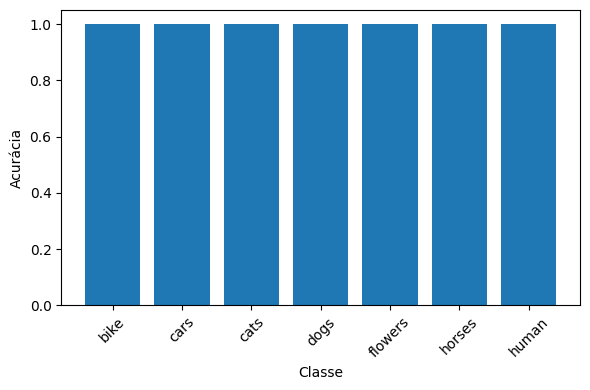

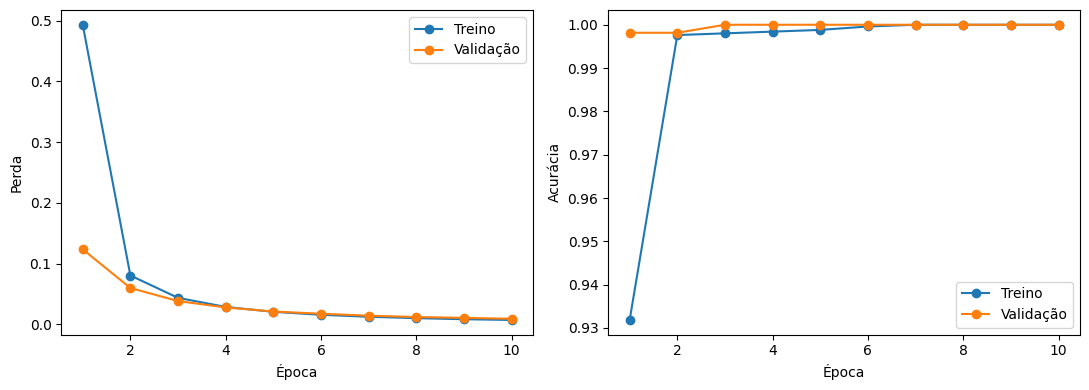

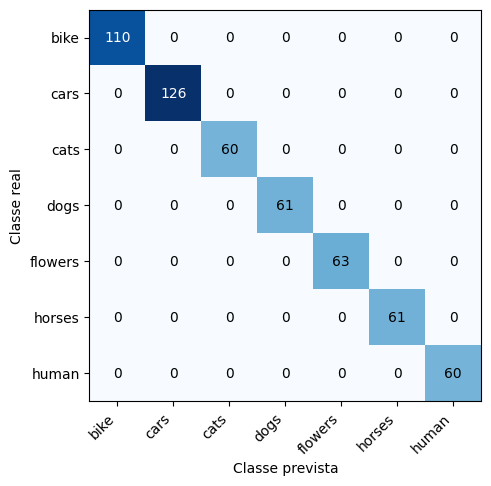

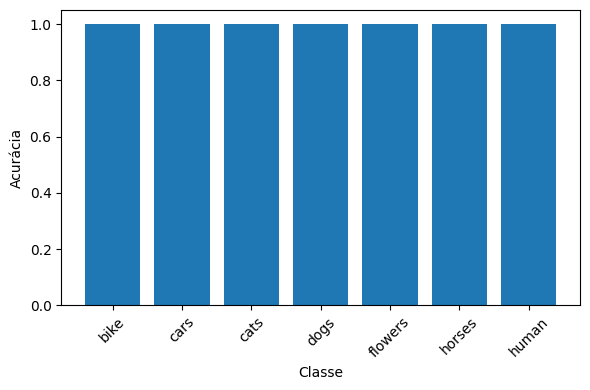

In [ ]:
report = evaluate(model, test_loader, DEVICE, num_classes=len(class_names))
print(f"acurácia global: {report['accuracy']:.4f}")
for name, value in zip(class_names, report["per_class_accuracy"]):
    print(f"{name}: {value:.4f}")

plot_history(history, FIGURES_DIR / "history.png")
plot_confusion(report["confusion"], class_names, FIGURES_DIR / "confusion.png")
plot_per_class_accuracy(report["per_class_accuracy"], class_names, FIGURES_DIR / "per_class.png")


In [ ]:
peak_memory = torch.cuda.max_memory_allocated() / 1e6 if DEVICE.type == "cuda" else 0.0
metrics = {
    "class_names": class_names,
    "class_counts": class_counts,
    "split_sizes": split_sizes,
    "hyperparameters": {
        "backbone": "resnet50 IMAGENET1K_V2",
        "batch_size": BATCH_SIZE,
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "optimizer": "Adam",
        "seed": SEED,
    },
    "total_parameters": total_parameters,
    "trainable_parameters": trainable_count,
    "history": history,
    "accuracy": report["accuracy"],
    "per_class_accuracy": dict(zip(class_names, report["per_class_accuracy"])),
    "confusion": report["confusion"],
    "runtime_seconds": round(time.time() - STARTED_AT, 1),
    "peak_gpu_memory_mb": round(peak_memory, 1),
}
(OUTPUT_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2))
print(make_archive("outputs_a3", "zip", OUTPUT_DIR))
print("tempo total (s):", metrics["runtime_seconds"])
print("pico de memória de GPU (MB):", metrics["peak_gpu_memory_mb"])


/content/outputs_a3.zip
tempo total (s): 197.0
pico de memória de GPU (MB): 465.8
